# Using a PDE as a reinforcement learning environment

We turn a PDE simulation into a [Gymnasium](https://gymnasium.farama.org/index.html) environment and run an episode with random actions. The same interface can be used to train an agent with libraries such as [Stable Baselines3](https://github.com/DLR-RM/stable-baselines3) or [SBX](https://github.com/araffin/sbx).

In [1]:
import gymnasium as gym
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from IPython.display import HTML
import matplotlib.animation as animation
import diffrax
from scipy.ndimage import zoom


from mosaix_pde.numerics.domains import Domain
from mosaix_pde.rl_utils import detect_vortices, density
from mosaix_pde.numerics.equations.gross_pitaevskii import GPE2DTSControl, hbar, mass_Na23, a0
from mosaix_pde.numerics.solvers import StrangSplitting
from mosaix_pde.numerics.utils.initialization_utils import initialize_Psi

The control task is to create vortices in a Bose–Einstein condensate by moving an external laser. We begin with the physical parameters of the condensate and its trap.

In [2]:
# Get variables with dimensions
atoms = 5e5 # number of atoms
omega = 2*jnp.pi*10 # 1/s (angular frequency of the trap in the x and y directions)
omega_z = jnp.sqrt(8)*omega # 1/s (angular frequency of the trap in the z direction)
epsilon = 0.0 # eccentricity of the trap
a_s = 100*a0 # s-wave scattering length

# Length of the x and y axes in meters
Lx = 150e-6 #meters
Ly = 150e-6 #meters

We use the trap frequency to set the time and length scales, then compute the dimensionless box size and coupling constant.

In [3]:
x_s = jnp.sqrt(hbar/(mass_Na23*omega)) # length scale
t_s = 1/omega # time scale

# Get dimensionless variables
Lx_ = Lx/x_s
Ly_ = Ly/x_s

# Get k
k = 4*jnp.pi*a_s*atoms*jnp.sqrt((mass_Na23*omega_z)/(2*jnp.pi*hbar)) # dimensionless coupling constant

We discretize the dimensionless domain on a 256 × 256 grid.

In [4]:
N = 256 # number of grid points
domain_ = Domain((N,N,), ((-Lx_/2, Lx_/2), (-Ly_/2, Ly_/2),), "dimensionless")

We normalize the initial wavefunction and use imaginary-time evolution to approximate the ground state.

In [5]:
Psi0 = initialize_Psi(N, width=100, vortexnumber=0)
Psi0_ = Psi0*x_s
Psi0_ /= jnp.sqrt(jnp.sum(density(Psi0_))*domain_.dx[0]**2)

In [6]:
eq = GPE2DTSControl(domain_, k, epsilon, lambda a,b,c: 0.0, trap_factor=1.0)
solver = StrangSplitting(eq.A_term, eq.domain.dx[0], eq.fft, eq.ifft, -1j)

In [7]:
solution = diffrax.diffeqsolve(
    diffrax.ODETerm(jax.jit(lambda t, y, args: eq.B_terms(y, t))),
    solver,
    t0=0.0,
    t1=0.05 / t_s,
    dt0=1e-5 / t_s,
    y0=jnp.stack([Psi0_.real, Psi0_.imag], axis=-1),
    saveat=diffrax.SaveAt(t1=True),
    max_steps=1000000,
)

ground_state = solution.ys[-1]

We use `PDEEnv-v0` to expose the simulation through Gymnasium. Calling `reset()` prepares an episode and returns the initial observation and an info dictionary. Calling `step(action)` advances the PDE and returns an observation, a reward, termination and truncation flags, and an info dictionary.

The following cells define what the agent observes, how it moves the laser, and how the environment scores each action.

`end_time` sets the duration of an episode. The agent chooses an action every `step_dt`, while the solver advances the PDE in smaller increments of `numeric_dt`. This lets the solver resolve the condensate dynamics between actions.

In [8]:
end_time = 1.0 / t_s
step_dt = 0.01 / t_s
numeric_dt = 1e-5 / t_s

At reset, we restore the ground state and place the laser at the origin.

In [9]:
def reset_function(domain):
    if ground_state.shape[:-1] != domain.points:
        # Reshape ground_state to match domain points
        zoom_factors = (domain.points[0] / ground_state.shape[0], 
                       domain.points[1] / ground_state.shape[1])
        resized = zoom(ground_state, zoom_factors, order=1)
        return resized
    return ground_state

reset_control_value = (0.0, 0.0)

The agent observes an image of the condensate density. We compute it from the real and imaginary parts of the wavefunction, then clip and scale it to an 8-bit grayscale image.

In [10]:
def state_to_observation(state):
    _density = density(state[...,0] + 1j*state[...,1])
    return (np.clip(np.array(_density), 0, 0.01) * 100 * 255).astype(np.uint8)[None]

The reward at each step is the number of detected vortices. The episode return is the sum of those rewards.

In [11]:
# reward function
def reward_function(state):
    psi = state[...,0] + 1j*state[...,1]
    vorts = detect_vortices(psi, amp_thresh=0.00005, tol=0.5)
    return vorts["num_vortices"]

Each action specifies a displacement from the current laser position. For the continuous action space used here, the two components give the horizontal and vertical displacements. Each component can take any value between `low` and `high`. For example, `(0, 0)` keeps the laser in place.

The alternative discrete configuration offers five choices. The laser can stay in place or move by a fixed distance in one of four directions.

In [12]:
continuous_action_space_config = {
    "type": "continuous",
    "shape": (2,),
    "low": float(-1e-5 / x_s),
    "high": float(1e-5 / x_s),
}

discrete_action_space_config = {
    "type": "discrete",
    "num_actions": 5,
    "action_mapping": {
        0: (0.0, 0.0), # no change
        1: (-0.5e-5 / x_s, 0.0), # move left
        2: (0.5e-5 / x_s, 0.0), # move right
        3: (0.0, -0.5e-5 / x_s), # move down
        4: (0.0, 0.5e-5 / x_s), # move up
    }
}

We add the displacement to the current laser position to obtain its position at the end of the step.

In [13]:
def update_control_value(action, old_control_value):
    return (old_control_value[0] + action[0], old_control_value[1] + action[1])

The PDE takes the laser-induced potential as an input. To convert the two laser positions into that potential, we move the center of a Gaussian along a straight line from the old position to the new one over `step_dt`.

In [14]:
def update_control_parameter(old_control_value, new_control_value):
    path_fn = lambda t: (
        old_control_value[0] + (new_control_value[0] - old_control_value[0]) * t / step_dt,
        old_control_value[1] + (new_control_value[1] - old_control_value[1]) * t / step_dt,
    )
    def light(t, xs, ys):
        A = 30.0
        sigma = 2e-6 / x_s
        xi, yi = path_fn(t)
        return A*jnp.exp(-((xs-xi)**2 + (ys-yi)**2)/(2.0*sigma**2))
    return light

We specify the fixed equation parameters and the solver settings separately from the laser control.

In [15]:
static_equation_parameters = {
    "k": k,
    "e": epsilon,
    "trap_factor": 1.0,
}

solver_parameters = {
    "time_scale": (1.0 - 1j*0.01),
}

We pass these settings to `gym.make` and select the continuous action space.

In [16]:
params = {
    "equation_type": GPE2DTSControl,
    "domain": domain_,
    "solver_type": StrangSplitting,
    "end_time": end_time,
    "step_dt": step_dt,
    "numeric_dt": numeric_dt,
    "state_to_observation_func": state_to_observation,
    "reward_function": reward_function,
    "reset_func": reset_function,
    "reset_control_value": reset_control_value,
    "update_control_value": update_control_value,
    "update_control_parameter": update_control_parameter,
    "action_space_config": continuous_action_space_config,
    "static_equation_parameters": static_equation_parameters,
    "control_equation_parameter_name": "lights",
    "solver_parameters": solver_parameters
}

In [17]:
env = gym.make('PDEEnv-v0', **params)

Inspect the action and observation spaces, then sample an action to see an example displacement.

In [18]:
print(f"Action space: {env.action_space}")
print(f"Sample action: {env.action_space.sample()}")
print(f"Observation space: {env.observation_space}")

Action space: Box(-1.5114268, 1.5114268, (2,), float32)
Sample action: [-0.33156982  1.3765533 ]
Observation space: Box(0, 255, (1, 256, 256), uint8)


Reset the environment and display the initial density image.

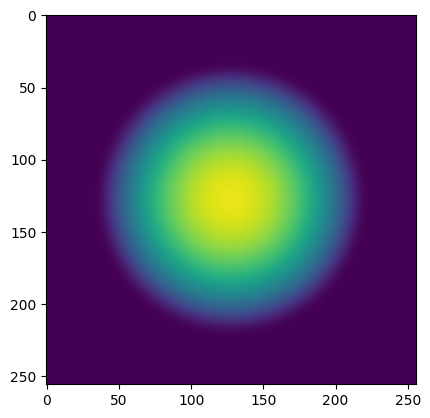

In [19]:
observation, info = env.reset()

plt.imshow(observation[0], vmin=0, vmax=255)
plt.show()

Take one random action, print its reward, and display the resulting observation.

reward:  0


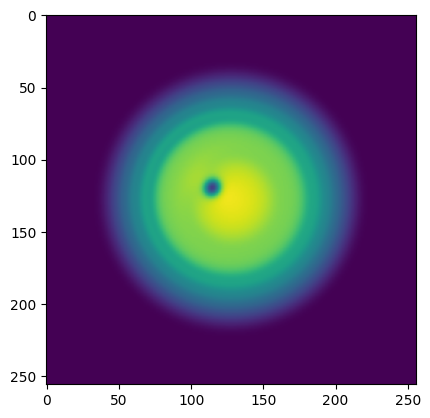

In [20]:
action = env.action_space.sample()
observation, reward, terminated, truncated, info = env.step(action)
print("reward: ", reward)
plt.imshow(observation[0], vmin=0, vmax=255)
plt.show()

Now run a full episode, sampling a new random action at each step. The animation shows the density and the reward for each displayed frame. The printed total includes the rewards from every step.

In [21]:
observation, info = env.reset()

episode_over = False
rewards = []
total_reward = 0

iters = 0

observations = []
while not episode_over:
    action = env.action_space.sample()

    observation, reward, terminated, truncated, info = env.step(action)

    total_reward += reward
    episode_over = terminated or truncated
    iters += 1
    rewards.append(reward)
    observations.append(observation[0])

print(f"Episode finished! Total reward: {total_reward}")
env.close()

Episode finished! Total reward: 503


In [22]:
fig, ax = plt.subplots(figsize=(4,4))

ims = []
for i in range(0, len(observations), 2):
    im = ax.imshow(observations[i], animated=True, 
                   vmin=0.0, vmax=255,
                   extent=[domain_.box[0][0], domain_.box[0][1], 
                          domain_.box[1][0], domain_.box[1][1]])
    title = ax.text(0.5, 1.05, f'Step {i}, Reward: {rewards[i]:.2f}',
                    ha='center', transform=ax.transAxes)
    ims.append([im, title])

ani = animation.ArtistAnimation(fig, ims, interval=100, blit=True)  # Increased interval from 20 to 200 ms

plt.xlabel('x')
plt.ylabel('y')

plt.close()

HTML(ani.to_jshtml())